# The total spectrum, no position selection (-82 V, DCRC1pB trigger)

*Eighth notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

The spectrum of all the events of the eight DCRC1pB-triggered series near -82 V, with **no cut on the position** (the delays) and no other selection than the trigger type. The pulses of these series are heavily saturated (see `spot-f-tight-traces.ipynb`), so the integral is far from linear in energy; this notebook starts from the plain distribution of one channel to see what it looks like before anything is done to it.

**So far: only the `integral` of Side2pF**, the centre disc, which is also the channel that triggers these series (DCRC1 pB). The integral is the sum of (sample - baseline) over the whole trace times the sample period, in ADC counts x s; the baseline is the mean of samples 10 to 500. Real triggers (label `Unknown`) and random triggers (label `Physics`; see `integral-on-the-face.ipynb`) are drawn separately.

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from goldpan.adapters import parquet
from spots_82v import OUT

q = parquet.read(OUT, detector="NAI-S2").quantities          # the quantities only, every event
trigger = np.asarray(q["trigger_type"]).astype(str)
F = np.asarray(q["Side2pF"]["integral"], dtype=float)        # ADC counts x s
real, rnd = trigger == "Unknown", trigger == "Physics"
print(f"{len(F):,} events: {real.sum():,} real triggers, {rnd.sum():,} random triggers")
for name, m in (("real triggers", real), ("random triggers", rnd)):
    p = np.percentile(F[m], [1, 10, 50, 90, 99])
    print(f"{name:>16}: Side2pF integral 1/10/50/90/99 %: " + "  ".join(f"{v:+.3f}" for v in p) + f";  largest {F[m].max():.3f}")

1,466,349 events: 1,436,655 real triggers, 29,694 random triggers
   real triggers: Side2pF integral 1/10/50/90/99 %: -0.478  +0.004  +0.519  +1.592  +2.139;  largest 2.586
 random triggers: Side2pF integral 1/10/50/90/99 %: -1.063  -0.149  -0.014  +0.193  +1.218;  largest 2.237


## The Side2pF integral

Counts per bin, on a linear and a log scale. The random triggers mark where an event with no pulse lands (around zero; a slow drift of the baseline over the trace spreads them, mostly to negative values).

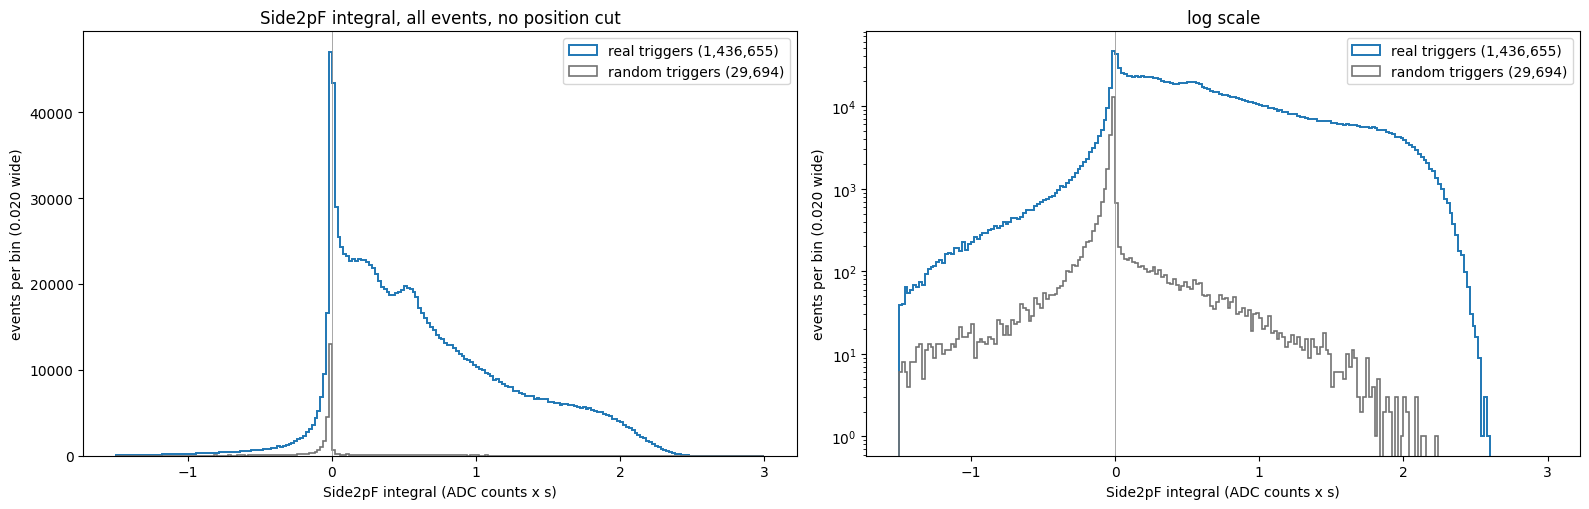

In [2]:
BINS = np.linspace(-1.5, 3.0, 226)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, log in zip(axes, (False, True)):
    ax.hist(F[real], bins=BINS, histtype="step", linewidth=1.4, color="C0", label=f"real triggers ({real.sum():,})")
    ax.hist(F[rnd], bins=BINS, histtype="step", linewidth=1.2, color="0.45", label=f"random triggers ({rnd.sum():,})")
    ax.axvline(0, color="0.6", linewidth=0.6)
    ax.set_xlabel("Side2pF integral (ADC counts x s)")
    ax.set_ylabel(f"events per bin ({BINS[1] - BINS[0]:.3f} wide)")
    if log:
        ax.set_yscale("log")
    ax.set_title("log scale" if log else "Side2pF integral, all events, no position cut")
    ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Reading it.** The largest integral Side2pF can reach is set by its saturated pulse height (about 880 counts above the baseline) held for the rest of the trace after the pulse starts (about 2.86 ms): about 2.5 ADC counts x s. Events near the top of the distribution are pulses that stay saturated to the end of the trace, so the shape there is set by the readout, not by the energy. Next: the other channels, and their sum, the same way.